# 09b — Diagnose Imbalance, Feature Treatment, and Decision Rules

Investigate why At risk detection is weak using controlled, staged experiments rather than adding model families. Object-oriented code is in `Python/imbalance_diagnostics.py`. This notebook is a diagnostic extension, not a replacement for the original results.

**Important:** previous validation results motivated this design, including the joint-income investigation. This is therefore validation-informed development. New sampler, treatment, and decision selections below use training CV only, but their external validation scores are not an unbiased final assessment. **No final test rows are read or resampled.** Keep the required three-class target and original cohort/split definitions.

In [1]:
import sys, json, platform
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import sklearn
from IPython.display import display, Markdown

PROJECT_ROOT = Path.cwd().parent if Path.cwd().name == 'notebooks' else Path.cwd()
sys.path.insert(0, str(PROJECT_ROOT))
from Python.imbalance_diagnostics import DiagnosticConfig, ImbalanceDiagnosticRunner

OUT = PROJECT_ROOT / 'outputs' / 'imbalance_diagnostics'
FIG = OUT / 'figures'
FIG.mkdir(parents=True, exist_ok=True)
config = DiagnosticConfig()
runner = ImbalanceDiagnosticRunner(PROJECT_ROOT, OUT, config)
metadata = {'configuration': config.to_dict(), 'split': runner.setup.split_config,
            'predictor_plan': runner.setup.predictor_plan['classification'],
            'python': platform.python_version(), 'numpy': np.__version__, 'sklearn': sklearn.__version__,
            'selection': 'Staged training CV mean macro F1; deterministic simpler ties',
            'validation_status': 'Already used for prior diagnosis; these are development comparisons',
            'test_policy': 'No final test data read',
            'preprocessing': 'Fit complete training fold before sampling; same statistics for sampler comparisons',
            'sample_weight_normalization': 'Uniform fitting weights sum to the original training-fold size',
            'auxiliary_input': 'annual_inc_joint: assumed available at origination, used only for three affordability ratios',
            'boosting_confirmation': 'Primary seed only; fixed Notebook 09 parameters; reuse exact reference if unchanged'}
(OUT / 'experiment_config.json').write_text(json.dumps(metadata, indent=2))
display(pd.Series(config.to_dict(), name='setting').to_frame())

,setting
seeds,"(42, 43, 44)"
policies,"(none, weighted, under, over, hybrid)"
treatments,"(current, original, joint, joint_robust)"
good_to_default_cap,2.0
target_risk_share_nonrisk,0.02
maximum_risk_replication,20
lower_quantile,0.005
upper_quantile,0.995
review_fraction,0.01
risk_thresholds,"(0.02, 0.05, 0.1, 0.2, 0.3, 0.4, 0.5, 0.6)"


## 1. What is already known

Only 611 of 451,671 training loans are At risk (0.135%); validation contains 9,491 of 678,142 (1.400%). The first CV training fold has 33 At risk examples. These are independent source observations; repeated copies are not additional independent evidence.

Good and Default describe terminal outcomes, while At risk is a temporary snapshot status. Unequal follow-up and the absence of historical label-observation dates complicate interpretation. The temporal pattern is consistent with snapshot effects but does not prove their cause. Sampling cannot establish missing historical outcomes or create new predictor information.

Prior validation At risk ROC AUC is around 0.65–0.68, while average precision is only about 0.026–0.032 against prevalence 0.014. Some ranking signal exists; poor default decisions and weak discrimination are separate possibilities. These observations motivate AP and fixed-budget diagnostics rather than accuracy alone.

In [2]:
distribution = pd.read_csv(PROJECT_ROOT / 'outputs/modelling_setup/target_distributions.csv')
display(distribution.query("task == 'classification'")[['partition', 'label', 'count', 'proportion']])
folds = pd.read_csv(PROJECT_ROOT / 'outputs/modelling_setup/cv_folds.csv').query("task == 'classification'")
display(folds[['fold', 'n_train', 'n_validation', 'train_class_1', 'validation_class_1']])
# Class counts by vintage use development data only; no outcome filtering is changed.
train, validation = runner.setup.load_classification()
audit_rows = []
for partition, frame in [('train', train), ('validation', validation)]:
    for year, group in frame.groupby(frame.issue_d.dt.year):
        audit_rows.append({'partition': partition, 'year': year, 'n': len(group),
                           'at_risk': int(group.target_class.eq(1).sum()),
                           'at_risk_share': group.target_class.eq(1).mean(),
                           'joint_applications': int(group.application_type.eq('Joint App').sum())})
audit = pd.DataFrame(audit_rows)
audit.to_csv(OUT / 'vintage_audit.csv', index=False)
display(audit)
del train, validation

,partition,label,count,proportion
2,train,0,374560.0,0.829276
3,train,1,611.0,0.001353
4,train,2,76500.0,0.169371
5,validation,0,524595.0,0.773577
6,validation,1,9491.0,0.013996
7,validation,2,144056.0,0.212427


,fold,n_train,n_validation,train_class_1,validation_class_1
5,1,258809,34449,33.0,83.0
6,2,293258,34370,116.0,86.0
7,3,327628,45416,202.0,138.0
8,4,373044,46182,340.0,150.0
9,5,419226,32445,490.0,121.0


,partition,year,n,at_risk,at_risk_share,joint_applications
0,train,2007,251,0,0.000000,0
1,train,2008,1562,0,0.000000,0
2,train,2009,4716,0,0.000000,0
3,train,2010,11536,0,0.000000,0
4,train,2011,21721,0,0.000000,0
5,train,2012,53367,0,0.000000,0
6,train,2013,134808,4,0.000030,0
7,train,2014,223710,607,0.002713,0
8,validation,2015,377796,2250,0.005956,403
9,validation,2016,300346,7241,0.024109,5508


## 2. Declared experiment matrix

**Stage A — sampling:** use the current feature set, logistic regression with fixed C=1, Newton-CG, at most 200 iterations, and tolerance 0.001. Compare:

| Policy | Fitting data/objective |
|---|---|
| none | Original training rows, ordinary loss |
| weighted | Original rows, balanced class weights from current fitting labels |
| under | Keep all At risk/Default; cap Good at twice the Default count |
| over | Keep every original; raise At risk toward 2% of non-risk rows, capped at 20× its original count |
| hybrid | Partial Good undersampling followed by the same capped At risk oversampling |

Random policies use seeds 42, 43, 44; deterministic none/weighted use seed 42 once. This is **55 logistic CV fits**. Samplers return source-row positions, preserving feature relationships; no synthetic records or SMOTE are used. Minority originals are retained. No sampler is automatically combined with balanced weights. Uniform fitting weights are normalized to the original fold size, keeping total loss weight comparable at fixed C; sampling still changes the estimator's empirical fitting distribution.

Fit imputation/encoding/scaling on the complete current training fold **before sampling** and reuse those statistics across policies. Evaluation is never sampled. All transformations remain training-only. This placement isolates sampler effects from sampler-dependent preprocessing changes. See the [imbalanced-learn leakage guidance](https://github.com/scikit-learn-contrib/imbalanced-learn/blob/master/doc/common_pitfalls.rst).

**Stage B — feature treatment:** fix the Stage A sampler, then compare current, original allowlist without engineered columns, joint affordability, and joint affordability plus robust transforms. Reuse the current-feature CV results; fit 15–45 additional logistic models depending on whether the chosen sampler is deterministic or stochastic.

**Stage C — decision rule:** use the chosen treatment's training out-of-fold probabilities to compare argmax with a declared grid of At risk thresholds. If p(At risk) exceeds a threshold predict At risk; otherwise choose between Good and Default. Select mean fold macro F1, averaging seeds within the same folds. This is threshold selection, not unbiased nested-CV evaluation. No validation thresholds are fitted.

**Stage D — boosting confirmation:** hold Notebook 09's 100 iterations, learning rate 0.1, 31 leaves, minimum leaf size 100, L2=1 and no random early stopping fixed. Apply the selected combined sampler/treatment using primary seed 42 in the same five folds. Compare with the matching balanced/current Notebook 09 reference. If the selected combination is unchanged, reuse that exact reference rather than claim a new independent experiment.

Use two native threads. Select every setting before this notebook scores external validation. This staged design does not exhaust sampling-strength/feature/model interactions and cannot prove that a factor is the sole cause of weak performance.

## 3. Feature policies and availability

- **current:** exact prior allowlist and feature formulas.
- **original:** remove engineered columns from the existing allowlist. This does not reconstruct every raw source feature; removing an engineered employment feature, for example, can remove information absent from the baseline allowlist.
- **joint:** recompute `loan_to_income`, `dti_x_loan_to_income`, and `installment_burden` using positive `annual_inc_joint` for Joint App, otherwise positive primary income for Individual. Missing/invalid joint income remains NaN, not zero or a substitute primary income. Preserve primary `annual_inc` as an input and primary `dti`; this is a limited affordability treatment, not a complete household-risk model. `rate_burden` has no income denominator and remains unchanged.
- **joint_robust:** joint policy plus 0.5–99.5% clipping bounds learned on each training fold's numeric columns. Apply log1p to the declared nonnegative skewed columns, treating negative values in those columns as missing before fold-wise imputation. Scaling follows these transforms.

Joint income is treated as an origination-time application input under the project's baseline-availability assumptions. It is auxiliary to those formulas, not an independent predictor. No verification-completion or post-outcome field is introduced. Joint applications are absent from the training/CV periods, so joint/current may be indistinguishable in CV. A tie cannot establish that the joint policy is unnecessary for future applications. Simpler ties are retained without consulting external validation. Previously generated datasets, predictor plans, and notebook scores are not overwritten.

In [3]:
treatment_rows = []
for treatment in config.treatments:
    pre = runner.preprocessor(treatment)
    treatment_rows.append({'treatment': treatment, 'numeric_predictors': len(pre.numeric),
                           'categorical_predictors': len(pre.categorical),
                           'joint_auxiliary_required': treatment in ['joint', 'joint_robust']})
treatment_manifest = pd.DataFrame(treatment_rows)
treatment_manifest.to_csv(OUT / 'treatment_manifest.csv', index=False)
display(treatment_manifest)
print('Log-transformed columns:', runner.preprocessor('joint_robust').LOG_COLUMNS)

,treatment,numeric_predictors,categorical_predictors,joint_auxiliary_required
0,current,39,5,False
1,original,24,5,False
2,joint,39,5,True
3,joint_robust,39,5,True


Log-transformed columns: ('annual_inc', 'loan_amnt', 'revol_bal', 'tot_cur_bal', 'tot_hi_cred_lim', 'bc_open_to_buy', 'loan_to_income', 'dti_x_loan_to_income', 'bc_pressure', 'installment_burden', 'loan_per_term', 'rate_burden')


## 4. Execute the staged experiment

Every metric uses all eligible fold-validation rows. Persist exact original/fitted class counts, number of distinct fitted rows, feature counts, seeds, timing, and warnings. CV prediction caches preserve source training-row positions for training-only decision analysis. Nonconverged logistic fits stop the run instead of silently entering selection.

After training-CV selection, score all declared logistic policies/treatments on the original complete external development validation cohort. Sampling seeds measure variability of the random treatment, not independent cohort uncertainty. Save only selected development models/predictions, plus compact scores/confusions for all treatments. Save/reload checks verify selected model probabilities.

In [4]:
sampling_cv, feature_cv, validation_scores = runner.run()
selection = json.loads((OUT / 'selection.json').read_text())
display(pd.Series(selection, name='selection'))
display(json.loads((OUT / 'execution_summary.json').read_text()))

logistic/current: fold 1, none, seed 42: macro F1=0.307


logistic/current: fold 1, weighted, seed 42: macro F1=0.365


logistic/current: fold 1, under, seed 42: macro F1=0.403


logistic/current: fold 1, under, seed 43: macro F1=0.403


logistic/current: fold 1, under, seed 44: macro F1=0.403


logistic/current: fold 1, over, seed 42: macro F1=0.307


... (119 outputs left out)

Validation: logistic_joint_robust_hybrid_43, macro F1=0.412


Validation: logistic_joint_robust_hybrid_44, macro F1=0.412


policy                                                       hybrid
treatment                                              joint_robust
risk_threshold                                                  0.3
source            Training CV only; staged selection, no validat...
criterion              Mean macro F1; simpler policies resolve ties
Name: selection, dtype: object

{'seconds': 356.0373710410058}

## 5. Did changing sampling help?

Selection uses mean macro F1. Separate fold standard deviation (after averaging seeds) from seed standard deviation (after averaging folds); they are not confidence intervals or 15 independent temporal replicates. Deterministic policies have no seed standard deviation. Keep AP, per-class recall/precision, and the review-budget result visible even when the primary selection metric improves.

,policy,macro_f1_mean,macro_f1_fold_std,macro_f1_seed_std,n_folds,n_seeds,risk_ap_mean,risk_recall_mean,risk_precision_mean,complexity
0,hybrid,0.411108,0.005174,0.000357,5,3,0.015252,0.015792,0.018914,4
1,under,0.406996,0.002831,0.000173,5,3,0.013622,0.000000,0.000000,2
2,weighted,0.353805,0.006755,NaN,5,1,0.014860,0.684367,0.011457,1
3,over,0.315032,0.006227,0.001064,5,3,0.015625,0.007254,0.020523,3
4,none,0.311486,0.004464,NaN,5,1,0.014220,0.000000,0.000000,0


,treatment,macro_f1_mean,macro_f1_fold_std,macro_f1_seed_std,n_folds,n_seeds,risk_ap_mean,risk_recall_mean,risk_precision_mean,complexity,selection_score
0,joint_robust,0.415476,0.004134,0.000566,5,3,0.016371,0.019810,0.037364,3,0.415476
1,current,0.411108,0.005174,0.000357,5,3,0.015252,0.015792,0.018914,0,0.411108
2,joint,0.411108,0.005174,0.000357,5,3,0.015252,0.015792,0.018914,2,0.411108
3,original,0.408934,0.004144,0.001033,5,3,0.015245,0.010973,0.020549,1,0.408934


,fold,policy,seed,n_train_original,n_train_fitted,n_distinct_fitted,original_class_1,fitted_class_0,fitted_class_1,fitted_class_2,uniform_weight_per_fitted_row
0,1,none,42,258809,258809,258809,33,218436,33,40340,1.000000
1,1,weighted,42,258809,258809,258809,33,218436,33,40340,1.000000
2,1,under,42,258809,121053,121053,33,80680,33,40340,2.137981
3,1,under,43,258809,121053,121053,33,80680,33,40340,2.137981
4,1,under,44,258809,121053,121053,33,80680,33,40340,2.137981
5,1,over,42,258809,259436,258809,33,218436,660,40340,0.997583
6,1,over,43,258809,259436,258809,33,218436,660,40340,0.997583
7,1,over,44,258809,259436,258809,33,218436,660,40340,0.997583
8,1,hybrid,42,258809,121680,121053,33,80680,660,40340,2.126964
9,1,hybrid,43,258809,121680,121053,33,80680,660,40340,2.126964


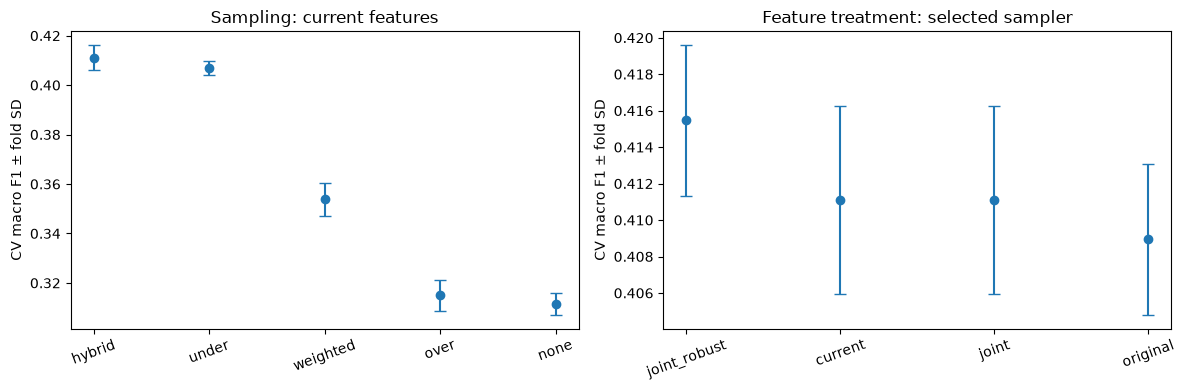

In [5]:
sampling_summary = pd.read_csv(OUT / 'sampling_cv_summary.csv')
feature_summary = pd.read_csv(OUT / 'feature_cv_summary.csv')
display(sampling_summary)
display(feature_summary)
counts = sampling_cv[['fold', 'policy', 'seed', 'n_train_original', 'n_train_fitted', 'n_distinct_fitted',
                      'original_class_1', 'fitted_class_0', 'fitted_class_1', 'fitted_class_2',
                      'uniform_weight_per_fitted_row']]
counts.to_csv(OUT / 'sampling_provenance.csv', index=False)
display(counts)
fig, axes = plt.subplots(1, 2, figsize=(12, 4))
for ax, frame, key, title in [(axes[0], sampling_summary, 'policy', 'Sampling: current features'),
                             (axes[1], feature_summary, 'treatment', 'Feature treatment: selected sampler')]:
    ax.errorbar(range(len(frame)), frame.macro_f1_mean, yerr=frame.macro_f1_fold_std, fmt='o', capsize=4)
    ax.set_xticks(range(len(frame)), frame[key], rotation=20)
    ax.set(title=title, ylabel='CV macro F1 ± fold SD')
fig.tight_layout()
fig.savefig(FIG / 'cv_ablation.png', dpi=150)
plt.show()

## 6. External development comparisons and seed variability

All settings were fixed by training CV before these scores were computed, but the validation period has already informed this project's development. Aggregate by seed for each fixed treatment/decision; do not use external means to revise the saved choice. A higher F1 with poor minority precision remains a weak risk detector.

,treatment,policy,decision,f1_macro_mean,f1_macro_std,accuracy_mean,accuracy_std,precision_class_1_mean,precision_class_1_std,recall_class_1_mean,...,precision_class_2_mean,precision_class_2_std,recall_class_2_mean,recall_class_2_std,risk_precision_at_budget_mean,risk_precision_at_budget_std,risk_recall_at_budget_mean,risk_recall_at_budget_std,auc_macro_ovr_mean,auc_macro_ovr_std
0,current,hybrid,argmax,0.411520,0.000310,0.768191,0.000204,0.077548,0.001324,0.012608,...,0.467956,0.000765,0.280863,0.001417,0.060896,0.000921,0.043515,0.000658,0.707895,0.000591
1,current,none,argmax,0.318805,NaN,0.776671,NaN,0.053763,NaN,0.000527,...,0.579546,NaN,0.044177,NaN,0.057063,NaN,0.040775,NaN,0.707400,NaN
2,current,over,argmax,0.325444,0.000230,0.775371,0.000087,0.067538,0.001870,0.014716,...,0.586367,0.000382,0.042433,0.000309,0.061978,0.001126,0.044288,0.000805,0.708534,0.000216
3,current,under,argmax,0.405053,0.000143,0.769215,0.000268,0.052237,0.003999,0.000597,...,0.467687,0.000930,0.281909,0.001125,0.057407,0.001107,0.041021,0.000791,0.707877,0.001102
4,current,weighted,argmax,0.377292,NaN,0.591153,NaN,0.032211,NaN,0.459277,...,0.326192,NaN,0.305659,NaN,0.057505,NaN,0.041092,NaN,0.657480,NaN
5,joint,hybrid,argmax,0.411942,0.000195,0.768441,0.000193,0.073880,0.001964,0.014048,...,0.469608,0.000747,0.279067,0.001329,0.060896,0.000921,0.043515,0.000658,0.708041,0.000591
6,joint_robust,hybrid,argmax,0.411813,0.000192,0.767600,0.000142,0.075503,0.001690,0.010923,...,0.465660,0.000532,0.286997,0.001077,0.059422,0.000532,0.042461,0.000380,0.708877,0.000469
7,joint_robust,hybrid,risk_threshold_0.3,0.414905,0.000339,0.766638,0.000183,0.068868,0.002864,0.019949,...,0.465384,0.000508,0.283961,0.000869,0.059422,0.000532,0.042461,0.000380,0.708877,0.000469
8,original,hybrid,argmax,0.409345,0.000979,0.769399,0.000234,0.073677,0.001566,0.010607,...,0.471551,0.000349,0.274160,0.001575,0.059963,0.000665,0.042848,0.000475,0.705772,0.000518


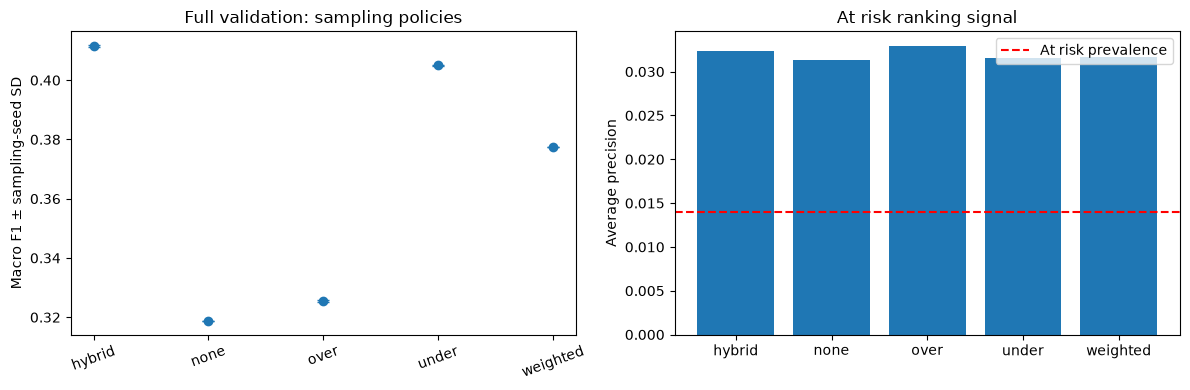

In [6]:
metrics = ['f1_macro', 'accuracy', 'precision_class_1', 'recall_class_1', 'ap_class_1',
           'precision_class_2', 'recall_class_2', 'risk_precision_at_budget', 'risk_recall_at_budget',
           'auc_macro_ovr']
external_summary = validation_scores.groupby(['treatment', 'policy', 'decision'])[metrics].agg(['mean', 'std'])
external_summary.columns = ['_'.join(col) for col in external_summary.columns]
external_summary = external_summary.reset_index()
external_summary.to_csv(OUT / 'validation_summary.csv', index=False)
display(external_summary)
fig, axes = plt.subplots(1, 2, figsize=(12, 4))
frame = external_summary.query("treatment == 'current' and decision == 'argmax'")
axes[0].errorbar(range(len(frame)), frame.f1_macro_mean, yerr=frame.f1_macro_std.fillna(0), fmt='o', capsize=4)
axes[0].set_xticks(range(len(frame)), frame.policy, rotation=20)
axes[0].set(title='Full validation: sampling policies', ylabel='Macro F1 ± sampling-seed SD')
axes[1].bar(frame.policy, frame.ap_class_1_mean)
axes[1].axhline(validation_scores.risk_prevalence.iloc[0], linestyle='--', color='red', label='At risk prevalence')
axes[1].set(title='At risk ranking signal', ylabel='Average precision')
axes[1].legend()
fig.tight_layout()
fig.savefig(FIG / 'validation_sampling.png', dpi=150)
plt.show()

## 7. Is the decision rule the problem?

The selected threshold is fixed using training out-of-fold predictions. The CV threshold score is optimistic because the same out-of-fold labels select the threshold; external development results assess its transfer. Default argmax and a fixed-threshold rule are distinct multiclass decisions, not calibrated probabilities.

At a 1% review budget, rank loans by At risk score without changing labels or sampling evaluation rows. Equal scores use seeded outcome-independent tie breaking. Compare precision and recall at that fixed budget. The prevalence reference is about 1.4%; reviewing 1% of the population cannot retrieve all At risk loans even with perfect ranking. These are diagnostic operating points, not a validated lending policy.

,decision,mean,std,prefer_default
0,0.3,0.416745,0.005052,False
1,argmax,0.415476,0.004175,True
2,0.2,0.413641,0.004601,False
3,0.4,0.413569,0.004558,False
4,0.5,0.411723,0.003407,False
5,0.6,0.410852,0.003001,False
6,0.1,0.393462,0.006627,False
7,0.05,0.362473,0.020664,False
8,0.02,0.330561,0.026887,False


,seed,decision,f1_macro,accuracy,precision_class_1,recall_class_1,ap_class_1,precision_class_2,recall_class_2,risk_precision_at_budget,risk_recall_at_budget,auc_macro_ovr
17,42,argmax,0.411649,0.767717,0.073692,0.010536,0.032581,0.466093,0.286937,0.059569,0.042567,0.709047
18,42,risk_threshold_0.3,0.415293,0.766772,0.071903,0.020546,0.032581,0.465762,0.283910,0.059569,0.042567,0.709047
19,43,argmax,0.412023,0.767443,0.077037,0.010958,0.032346,0.465067,0.288103,0.059864,0.042777,0.708347
20,43,risk_threshold_0.3,0.414759,0.766429,0.066213,0.019492,0.032346,0.464807,0.284855,0.059864,0.042777,0.708347
21,44,argmax,0.411767,0.767642,0.075779,0.011274,0.032713,0.465821,0.285951,0.058832,0.042040,0.709237
22,44,risk_threshold_0.3,0.414665,0.766713,0.068488,0.019808,0.032713,0.465582,0.283119,0.058832,0.042040,0.709237


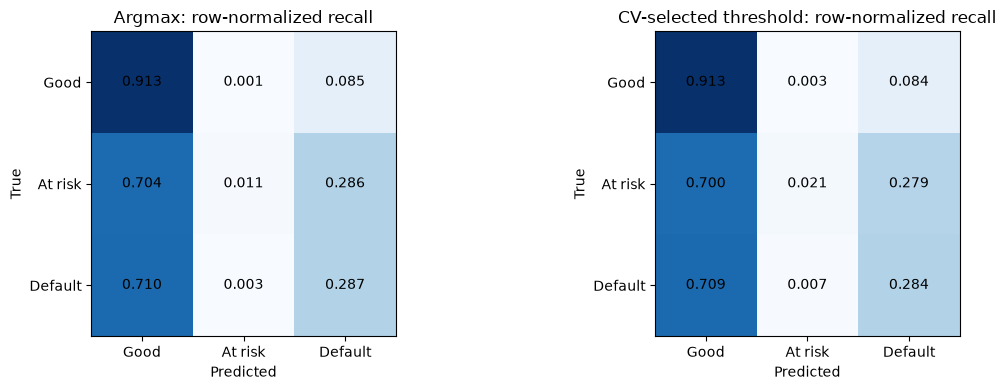

In [7]:
display(pd.read_csv(OUT / 'decision_cv_summary.csv'))
chosen_validation = validation_scores[(validation_scores.policy == selection['policy']) &
                                      (validation_scores.treatment == selection['treatment'])]
display(chosen_validation[['seed', 'decision'] + metrics])
seed = config.seeds[0]
label = f"logistic_{selection['treatment']}_{selection['policy']}_{seed}"
paths = [(OUT / f'{label}_confusion.csv', 'Argmax')]
if selection['risk_threshold'] is not None:
    paths.append((OUT / f'{label}_threshold_confusion.csv', 'CV-selected threshold'))
fig, axes = plt.subplots(1, len(paths), figsize=(6 * len(paths), 4), squeeze=False)
for ax, (path, title) in zip(axes[0], paths):
    matrix = pd.read_csv(path, index_col=0)
    values = matrix.to_numpy() / matrix.sum(axis=1).to_numpy()[:, None]
    ax.imshow(values, cmap='Blues')
    for (i, j), value in np.ndenumerate(values):
        ax.text(j, i, f'{value:.3f}', ha='center', va='center')
    ax.set(xticks=range(3), yticks=range(3), xticklabels=matrix.columns, yticklabels=matrix.index,
           xlabel='Predicted', ylabel='True', title=f'{title}: row-normalized recall')
fig.tight_layout()
fig.savefig(FIG / 'decision_confusion.png', dpi=150)
plt.show()

## 8. Does the treatment transfer to boosting?

Use fixed Notebook 09 boosting parameters and primary sampling seed 42; no second tree-parameter search is performed. The comparison checks the combined selected treatment, not each factor in isolation. The matched Notebook 09 reference has identical folds, rows, and hyperparameters. If the combination is unchanged, a reused result is explicitly labelled and is not independent confirmation. Sampling-seed stability for boosting is not assessed in this budget.

In [8]:
confirmation = pd.read_csv(OUT / 'boosting_confirmation_validation.csv')
prior_boost = pd.read_csv(PROJECT_ROOT / 'outputs/ensembles/classification_validation_scores.csv').query("model == 'hist_gradient_boosting'")
prior_pred = pd.read_parquet(PROJECT_ROOT / 'outputs/ensembles/classification_hist_gradient_boosting_validation_predictions.parquet')
from Python.imbalance_diagnostics import ImbalanceMetrics
reference = ImbalanceMetrics(config).score(prior_pred.target_class,
    prior_pred[[f'probability_{c}' for c in [0, 1, 2]]].to_numpy())
boost_comparison = pd.DataFrame([{'variant': 'Notebook 09 balanced/current', **reference},
                                {'variant': '09b selected treatment', **confirmation.iloc[0].to_dict()}])
boost_comparison.to_csv(OUT / 'boosting_comparison.csv', index=False)
display(boost_comparison[['variant', 'reference_reused'] + metrics])
display(pd.read_csv(OUT / 'boosting_confirmation_cv.csv'))

,variant,reference_reused,f1_macro,accuracy,precision_class_1,recall_class_1,ap_class_1,precision_class_2,recall_class_2,risk_precision_at_budget,risk_recall_at_budget,auc_macro_ovr
0,Notebook 09 balanced/current,NaN,0.421880,0.666474,0.037509,0.099252,0.028416,0.357406,0.550230,0.039959,0.028553,0.696218
1,09b selected treatment,False,0.413676,0.767612,0.058552,0.004004,0.029022,0.465273,0.311476,0.043792,0.031293,0.708591


,family,policy,seed,n_train_original,n_train_fitted,n_distinct_fitted,uniform_weight_per_fitted_row,n_evaluation,n_features,fit_predict_seconds,...,risk_recall_at_budget,original_class_0,fitted_class_0,original_class_1,fitted_class_1,original_class_2,fitted_class_2,treatment,fold,reference_reused
0,boosting,hybrid,42,258809,121680,121053,2.126964,34449,112,16.938572,...,0.048193,218436,80680,33,660,40340,40340,joint_robust,1,False
1,boosting,hybrid,42,293258,141547,139343,2.071807,34370,112,19.760479,...,0.046512,246733,92818,116,2320,46409,46409,joint_robust,2,False
2,boosting,hybrid,42,327628,161737,158767,2.025684,45416,112,22.377103,...,0.028986,274571,105710,202,3172,52855,52855,joint_robust,3,False
3,boosting,hybrid,42,373044,187780,184438,1.986601,46182,112,25.867294,...,0.066667,311338,122732,340,3682,61366,61366,joint_robust,4,False
4,boosting,hybrid,42,419226,215265,211534,1.947488,32445,113,21.306468,...,0.074380,348388,140696,490,4221,70348,70348,joint_robust,5,False


## 9. Interpretation and limits

The generated assessment distinguishes class weighting/sampling, feature treatment, ranking, and decision effects. No result proves that data or models alone are responsible. The sampler strengths are fixed diagnostic choices rather than an exhaustive search. Feature/sampler interactions beyond the staged comparison, probability calibration, a fixed-horizon outcome design, and genuinely new independent minority examples remain separate questions.

This notebook deliberately preserves the required three classes. It does not silently merge At risk with Default, use post-origination fields, randomize the temporal split, or rebalance validation/test. Joint affordability revises a known treatment weakness under explicit input-availability assumptions, and its validation-informed origin must be disclosed in the final report.

In [9]:
lines = ['# Notebook 09b — observed diagnostic results', '']
lines.append(f"Training-CV sampler choice: **{selection['policy']}**; feature choice: **{selection['treatment']}**; risk threshold: **{selection['risk_threshold']}** (None means argmax).")
for _, row in external_summary.query("treatment == 'current' and decision == 'argmax'").iterrows():
    lines.append(f"- Sampling **{row.policy}**: validation macro F1 **{row.f1_macro_mean:.3f}**, At risk precision **{row.precision_class_1_mean:.2%}**, recall **{row.recall_class_1_mean:.2%}**, AP **{row.ap_class_1_mean:.4f}**.")
lines.append('')
for _, row in external_summary[external_summary.policy == selection['policy']].iterrows():
    lines.append(f"- Features **{row.treatment}**, decision **{row.decision}**: macro F1 **{row.f1_macro_mean:.3f}**, At risk AP **{row.ap_class_1_mean:.4f}**, recall **{row.recall_class_1_mean:.2%}**; top-1% review precision **{row.risk_precision_at_budget_mean:.2%}**, recall **{row.risk_recall_at_budget_mean:.2%}**.")
lines += ['', f"Boosting confirmation: macro F1 **{confirmation.iloc[0].f1_macro:.3f}**, versus **{reference['f1_macro']:.3f}** for the matched Notebook 09 reference; reference reused: **{confirmation.iloc[0].reference_reused}**.",
          '- Interpret precision and recall jointly. Oversampling duplicates independent observations; it does not increase their number. Partial undersampling can discard useful majority information. Balanced weights and sampling need not improve the same classes.',
          '- AP and review-budget metrics assess ranking separately from argmax/threshold decisions. A threshold can redistribute errors without creating predictive signal. Joint/current CV ties are expected when no joint applications occur in training/CV.',
          '- Validation already informed this diagnostic design. These are development comparisons, not final-test claims; no final test rows were read.',
          f"- Experiment runtime: **{json.loads((OUT / 'execution_summary.json').read_text())['seconds'] / 60:.2f} minutes**."]
interpretation = '\n'.join(lines)
display(Markdown(interpretation))
_ = (OUT / 'analysis.md').write_text(interpretation)

# Notebook 09b — observed diagnostic results

Training-CV sampler choice: **hybrid**; feature choice: **joint_robust**; risk threshold: **0.3** (None means argmax).
- Sampling **hybrid**: validation macro F1 **0.412**, At risk precision **7.75%**, recall **1.26%**, AP **0.0324**.
- Sampling **none**: validation macro F1 **0.319**, At risk precision **5.38%**, recall **0.05%**, AP **0.0314**.
- Sampling **over**: validation macro F1 **0.325**, At risk precision **6.75%**, recall **1.47%**, AP **0.0329**.
- Sampling **under**: validation macro F1 **0.405**, At risk precision **5.22%**, recall **0.06%**, AP **0.0316**.
- Sampling **weighted**: validation macro F1 **0.377**, At risk precision **3.22%**, recall **45.93%**, AP **0.0317**.

- Features **current**, decision **argmax**: macro F1 **0.412**, At risk AP **0.0324**, recall **1.26%**; top-1% review precision **6.09%**, recall **4.35%**.
- Features **joint**, decision **argmax**: macro F1 **0.412**, At risk AP **0.0324**, recall **1.40%**; top-1% review precision **6.09%**, recall **4.35%**.
- Features **joint_robust**, decision **argmax**: macro F1 **0.412**, At risk AP **0.0325**, recall **1.09%**; top-1% review precision **5.94%**, recall **4.25%**.
- Features **joint_robust**, decision **risk_threshold_0.3**: macro F1 **0.415**, At risk AP **0.0325**, recall **1.99%**; top-1% review precision **5.94%**, recall **4.25%**.
- Features **original**, decision **argmax**: macro F1 **0.409**, At risk AP **0.0319**, recall **1.06%**; top-1% review precision **6.00%**, recall **4.28%**.

Boosting confirmation: macro F1 **0.414**, versus **0.422** for the matched Notebook 09 reference; reference reused: **False**.
- Interpret precision and recall jointly. Oversampling duplicates independent observations; it does not increase their number. Partial undersampling can discard useful majority information. Balanced weights and sampling need not improve the same classes.
- AP and review-budget metrics assess ranking separately from argmax/threshold decisions. A threshold can redistribute errors without creating predictive signal. Joint/current CV ties are expected when no joint applications occur in training/CV.
- Validation already informed this diagnostic design. These are development comparisons, not final-test claims; no final test rows were read.
- Experiment runtime: **5.93 minutes**.

## 10. Assessment of the observed results

The diagnostic below reads saved results and model state, without fitting or changing selected settings.

In [1]:
import joblib
scores = pd.read_csv(OUT / 'validation_scores.csv')
selection = json.loads((OUT / 'selection.json').read_text())
chosen_policy = selection['policy']
means = scores.groupby(['treatment', 'policy', 'decision']).mean(numeric_only=True)
weighted = means.loc[('current', 'weighted', 'argmax')]
none = means.loc[('current', 'none', 'argmax')]
under = means.loc[('current', 'under', 'argmax')]
hybrid = means.loc[('current', 'hybrid', 'argmax')]
robust = means.loc[('joint_robust', chosen_policy, 'argmax')]
chosen_argmax = means.loc[(selection['treatment'], chosen_policy, 'argmax')]
current_chosen = means.loc[('current', chosen_policy, 'argmax')]
decision = 'argmax' if selection['risk_threshold'] is None else f"risk_threshold_{selection['risk_threshold']}"
thresholded = means.loc[(selection['treatment'], chosen_policy, decision)]
boost = pd.read_csv(OUT / 'boosting_confirmation_validation.csv').iloc[0]
reference = pd.read_csv(PROJECT_ROOT / 'outputs/ensembles/classification_validation_scores.csv').query("model == 'hist_gradient_boosting'").iloc[0]
selection = json.loads((OUT / 'selection.json').read_text())
bundle = joblib.load(OUT / f"logistic_{selection['treatment']}_{selection['policy']}_42_model.joblib")
pre = bundle['preprocessing']
if pre.bounds_ is not None:
    bounds = pre.bounds_.T.copy()
    bounds.columns = ['training_lower_bound', 'training_upper_bound']
    bounds.to_csv(OUT / 'selected_training_clip_bounds.csv')
    display(bounds)
schema = {'raw_model_columns': pre.columns,
          'auxiliary_columns': ['annual_inc_joint'] if pre.treatment in ['joint', 'joint_robust'] else [],
          'encoded_columns': pre.preprocessor_._pipeline.named_steps['pre'].get_feature_names_out().tolist(),
          'joint_income_policy': 'Joint App: positive joint income; otherwise Individual primary income; absent joint income remains NaN',
          'probability_warning': 'Resampled/weighted scores are not calibrated population risks'}
_ = (OUT / 'selected_input_schema.json').write_text(json.dumps(schema, indent=2))

notes = f"""
## What this experiment tells us

**Sampling affects the fitting objective, but higher macro F1 is not the same as better At risk detection.** At current features, undersampling increases validation macro F1 from {none.f1_macro:.3f} to {under.f1_macro:.3f}. Default recall rises from {none.recall_class_2:.1%} to {under.recall_class_2:.1%}, while At risk recall remains about {under.recall_class_1:.2%}. The hybrid gives macro F1 {hybrid.f1_macro:.3f}, but At risk recall only {hybrid.recall_class_1:.2%}. Balanced weights instead give {weighted.recall_class_1:.1%} At risk recall with only {weighted.precision_class_1:.2%} precision. These are different operating tradeoffs, not evidence that one configuration solves the rare class.

**Ranking signal barely changes.** At risk average precision stays around 0.031–0.033 across the logistic sampling policies, against validation prevalence {weighted.risk_prevalence:.3f}. Oversampling alone makes only a small difference. Changing how often existing records are fitted does not supply new independent minority examples or guarantee better separation. This supports investigating predictor information, temporal/snapshot labels and representation as well as imbalance; it does not prove that the data are intrinsically unlearnable or that every resampling method would fail.

**Feature handling matters for numerical validity, but the tested revision is not a large classification improvement.** Joint/current have identical CV results because there are no joint applications in those training/CV periods. Robust treatment improves CV modestly, yet validation macro F1 is {robust.f1_macro:.3f} versus {current_chosen.f1_macro:.3f} for current features with the same selected sampler. Removing engineered columns gives a similarly small change. These results do not implicate engineered features as the main source of weak At risk detection. The primary-income ratio issue remains a real input-support problem, especially for extrapolating models; its correction should not be described as a demonstrated rare-class solution.

**Decision rules move errors, with limited practical gain here.** The selected treatment has argmax validation At risk recall {chosen_argmax.recall_class_1:.2%} and selected-rule recall {thresholded.recall_class_1:.2%}, while precision changes from {chosen_argmax.precision_class_1:.2%} to {thresholded.precision_class_1:.2%}. Nearly all At risk cases are still missed at this selected operating point. The fixed 1% review budget obtains precision {chosen_argmax.risk_precision_at_budget:.2%} and recall {chosen_argmax.risk_recall_at_budget:.2%}: above a random-prevalence reference, but still weak. A review budget and acceptable precision/recall must be chosen for the intended use; macro F1 alone can favor a model that effectively neglects one class.

**The selected treatment does not transfer as an overall boosting improvement.** Boosting validation macro F1 is {boost.f1_macro:.3f}, versus {reference.f1_macro:.3f} for Notebook 09. At risk recall is {boost.recall_class_1:.2%}, versus {reference.recall_class_1:.2%}; Default recall is {boost.recall_class_2:.2%}, versus {reference.recall_class_2:.2%}. Better logistic CV scores did not identify a universally better boosting treatment. Keep the original ensemble results; do not overwrite them with a claimed repair.

**Recommended next steps:** retain this diagnostic in the report, predeclare class-specific or review-budget objectives, and continue model comparisons without claiming imbalance has been solved. Probability calibration, broader sampler strengths or representations, and genuinely additional independent At risk examples remain possible investigations. A fixed-horizon label audit would help assess unequal follow-up if suitable outcome timing exists; do not invent missing dates or silently replace the project's three-class target. Final test data remain unread.
"""
display(Markdown(notes))
analysis = OUT / 'analysis.md'
base = analysis.read_text().split('\n## What this experiment tells us')[0].rstrip()
_ = analysis.write_text(base + '\n' + notes)


,training_lower_bound,training_upper_bound
loan_amnt,1275.000000,35000.000000
term,36.000000,60.000000
annual_inc,15000.000000,300000.000000
dti,0.940000,36.290000
fico_range_low,660.000000,805.000000
fico_range_high,664.000000,809.000000
delinq_2yrs,0.000000,5.000000
inq_last_6mths,0.000000,5.000000
open_acc,3.000000,29.000000
total_acc,5.000000,63.000000



## What this experiment tells us

**Sampling affects the fitting objective, but higher macro F1 is not the same as better At risk detection.** At current features, undersampling increases validation macro F1 from 0.319 to 0.405. Default recall rises from 4.4% to 28.2%, while At risk recall remains about 0.06%. The hybrid gives macro F1 0.412, but At risk recall only 1.26%. Balanced weights instead give 45.9% At risk recall with only 3.22% precision. These are different operating tradeoffs, not evidence that one configuration solves the rare class.

**Ranking signal barely changes.** At risk average precision stays around 0.031–0.033 across the logistic sampling policies, against validation prevalence 0.014. Oversampling alone makes only a small difference. Changing how often existing records are fitted does not supply new independent minority examples or guarantee better separation. This supports investigating predictor information, temporal/snapshot labels and representation as well as imbalance; it does not prove that the data are intrinsically unlearnable or that every resampling method would fail.

**Feature handling matters for numerical validity, but the tested revision is not a large classification improvement.** Joint/current have identical CV results because there are no joint applications in those training/CV periods. Robust treatment improves CV modestly, yet validation macro F1 is 0.412 versus 0.412 for current features with the same selected sampler. Removing engineered columns gives a similarly small change. These results do not implicate engineered features as the main source of weak At risk detection. The primary-income ratio issue remains a real input-support problem, especially for extrapolating models; its correction should not be described as a demonstrated rare-class solution.

**Decision rules move errors, with limited practical gain here.** The selected treatment has argmax validation At risk recall 1.09% and selected-rule recall 1.99%, while precision changes from 7.55% to 6.89%. Nearly all At risk cases are still missed at this selected operating point. The fixed 1% review budget obtains precision 5.94% and recall 4.25%: above a random-prevalence reference, but still weak. A review budget and acceptable precision/recall must be chosen for the intended use; macro F1 alone can favor a model that effectively neglects one class.

**The selected treatment does not transfer as an overall boosting improvement.** Boosting validation macro F1 is 0.414, versus 0.422 for Notebook 09. At risk recall is 0.40%, versus 9.93%; Default recall is 31.15%, versus 55.02%. Better logistic CV scores did not identify a universally better boosting treatment. Keep the original ensemble results; do not overwrite them with a claimed repair.

**Recommended next steps:** retain this diagnostic in the report, predeclare class-specific or review-budget objectives, and continue model comparisons without claiming imbalance has been solved. Probability calibration, broader sampler strengths or representations, and genuinely additional independent At risk examples remain possible investigations. A fixed-horizon label audit would help assess unequal follow-up if suitable outcome timing exists; do not invent missing dates or silently replace the project's three-class target. Final test data remain unread.
